# GAN Intrusion Detection · versione corretta

Progetto del corso Sicurezza delle Architetture Orientate ai Servizi · Università degli Studi di Milano · ottobre 2025, corretto a novembre 2026<br>
Autori: Gaetano Angelo Alberto Loizzo, Michele Vulpio

Versione corretta di [`GAN_Intrusion_Detection.ipynb`](GAN_Intrusion_Detection.ipynb). Rispetto all'originale cambiano tre cose:

1. **La GAN si addestra senza warm-up** (`warm_up_epochs=0`): generatore e discriminatore si allenano insieme dalla prima epoca. Nell'originale il codice del template usava 10 epoche di warm-up come valore predefinito: per 9 epoche si addestrava solo il discriminatore e il generatore non riusciva più a recuperare.
2. **Tutte le tracce hanno al massimo 100 chiamate.** La GCN usa solo le prime 100 system call di ogni traccia reale, come le tracce generate dalla GAN, a cui vengono tolti gli zeri finali di riempimento (padding). Così la lunghezza non distingue più le tracce sintetiche da quelle reali.
3. **Il controllo di realismo usa tutti i grafi generati**, non uno solo, e applica lo stesso criterio anche agli attacchi reali come termine di paragone.

Dati, split, modelli e iperparametri sono gli stessi dell'originale. Risultati e analisi sono nel [README del repository](https://github.com/GaetanoAA/GAN_Intrusion_Detection#readme).

Il notebook parte da `train_evaluate_models.ipynb` del template [gweldit/VanillaGAN](https://github.com/gweldit/VanillaGAN), che fornisce anche i moduli importati più avanti. Il template è distribuito con licenza Apache 2.0 (copia in `third_party/`).

**Per eseguirlo su Colab** (runtime con GPU): scarica ADFA-LD dalla [pagina ufficiale UNSW](https://research.unsw.edu.au/projects/adfa-ids-datasets), carica in `/content` uno zip `ADFA-LD.zip` che contenga la cartella `ADFA-LD` con `Training_Data_Master`, `Validation_Data_Master` e `Attack_Data_Master`, poi esegui tutte le celle.

# Setting dell'Ambiente di Lavoro

In [1]:
!git clone https://github.com/gweldit/VanillaGAN
!git -C VanillaGAN checkout -q 0aa64f9  # versione del template usata nell'esecuzione (aprile 2025)

fatal: destination path 'VanillaGAN' already exists and is not an empty directory.


In [2]:
!pip install -r /content/VanillaGAN/requirements.txt

In [3]:
%cd /content/VanillaGAN

/content/VanillaGAN


In [4]:
import networkx as nx
import matplotlib.pyplot as plt
import torch
import numpy as np
from collections import Counter
from torch_geometric.loader import DataLoader
import torch.nn as nn
from torch.optim import Adam
from torch.nn.utils.rnn import pad_sequence
from sklearn.model_selection import train_test_split

from pathlib import Path
import os

# custom modules
from models import Generator, Discriminator
from custom_dataset import CustomSequenceDataset
from preprocess_data import read_adfa_data, sequence_to_graph, fetch_graph_data
from utils import get_device, plot_loss_curve, evaluate_gcn_model
from classifiers import GCNModel
from train import train_gan_model
from train import train_gcn_model
from models import init_weights

In [5]:
# for reproducibility
import random

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

## Read, Preprocess, e Fetch the ADFA datasets


In [6]:
data_folder = "ADFA-LD"
current_directory = Path(os.getcwd())
parent_path = current_directory.parent.absolute()

full_data_folder_path = os.path.join(parent_path, data_folder)

In [7]:
# 1) estrai lo zip
!rm -rf /content/ADFA-LD
!unzip -q "/content/ADFA-LD.zip" -d /content/

# 2) se lo zip crea sottocartelle (es. ADFA-IDS_DATASETS/ADFA-LD), sposta/rinomina
import os, glob, shutil

# cerca una cartella che contenga le tre sottocartelle richieste
candidates = [p for p in glob.glob("/content/**/ADFA-LD", recursive=True) if os.path.isdir(p)]
if candidates:
    src = candidates[0]
    if src != "/content/ADFA-LD":
        shutil.move(src, "/content/ADFA-LD")
else:
    # piano B: trova la cartella che contiene Training_Data_Master
    tdm = [p for p in glob.glob("/content/**/Training_Data_Master", recursive=True) if os.path.isdir(p)]
    if tdm:
        src = os.path.dirname(tdm[0])
        if os.path.basename(src) != "ADFA-LD":
            shutil.move(src, "/content/ADFA-LD")

# 3) verifica struttura
ok = []
for sub in ["Training_Data_Master","Validation_Data_Master","Attack_Data_Master"]:
    path = f"/content/ADFA-LD/{sub}"
    ok.append(os.path.exists(path))
    print(sub, "->", os.path.exists(path))
if all(ok):
    print("\nTutto ok: il codice troverà il dataset in /content/ADFA-LD ✅")
    print("Esempio file:", os.listdir("/content/ADFA-LD/Training_Data_Master")[:5])
else:
    print("\n⚠️ Struttura non completa. Controlla che lo zip contenga le tre cartelle richieste.")


Training_Data_Master -> True
Validation_Data_Master -> True
Attack_Data_Master -> True

Tutto ok: il codice troverà il dataset in /content/ADFA-LD ✅
Esempio file: ['UTD-0582.txt', 'UTD-0287.txt', 'UTD-0655.txt', 'UTD-0192.txt', 'UTD-0465.txt']


In [8]:
adfa_sub_folders = [
    "Training_Data_Master",
    "Validation_Data_Master",
    "Attack_Data_Master",
]

benign_training_data_path = os.path.join(full_data_folder_path, adfa_sub_folders[0])
benign_validation_data_path = os.path.join(full_data_folder_path, adfa_sub_folders[1])

attack_data_path = os.path.join(full_data_folder_path, adfa_sub_folders[2])


# read the sub folders
benign_train_sequences, benign_train_labels = read_adfa_data(benign_training_data_path)

benign_val_sequences, benign_val_labels = read_adfa_data(benign_validation_data_path)

attack_sequences, attack_labels = read_adfa_data(attack_data_path)


data = benign_train_sequences + benign_val_sequences + attack_sequences
labels = benign_train_labels + benign_val_labels + attack_labels

# perform  70 % training and 30% testing set split

train_data, test_data, train_labels, test_labels = train_test_split(
    data, labels, test_size=0.3, random_state=42, shuffle=True, stratify=labels
)

len(train_data), len(train_labels), len(test_data), len(test_labels)

Read 833 sequences from Training_Data_Master
Read 4372 sequences from Validation_Data_Master
Read 746 sequences from Attack_Data_Master


(4165, 4165, 1786, 1786)

In [9]:
len(attack_sequences)

746

In [10]:
# Data is imbalanced: 3643 benign & 522 attack (malicious) sequences will be used for training the GCN model
Counter(train_labels)

Counter({0: 3643, 1: 522})

In [11]:
Counter(test_labels)

Counter({0: 1562, 1: 224})

## Lunghezza delle tracce

Le tracce generate dalla GAN hanno al massimo 100 chiamate (`SEQUENCE_LENGTH`), mentre quelle reali arrivano a migliaia. Per non dare al classificatore una scorciatoia, la GCN usa solo le prime `MAX_CALLS` chiamate di ogni traccia, reale o sintetica, in tutti gli esperimenti.

In [12]:
MAX_CALLS = 100  # numero massimo di system call per traccia, uguale per tracce reali e sintetiche

In [13]:
# Create a custom dataset
batch_size = 64
# convert train_data sequences and val_data sequences into graphs

# la GCN usa solo le prime MAX_CALLS chiamate di ogni traccia
train_graph_dataset = fetch_graph_data([seq[:MAX_CALLS] for seq in train_data], train_labels)
val_graph_dataset = fetch_graph_data([seq[:MAX_CALLS] for seq in test_data], test_labels)


# Create a data loader
graph_train_loader = DataLoader(
    train_graph_dataset, batch_size=batch_size, shuffle=True
)
graph_val_loader = DataLoader(val_graph_dataset, batch_size=batch_size, shuffle=False)

In [14]:
# you can see the graph data: it has edge_index, weight, num_nodes, y (label of the graph, i.e., malign or benign), and x (node features). Here, x is a list of integers representing the node features. They need to be converted to a one-hot vector of size vocab_size or vector of embedded representation.
train_graph_dataset[0]

Data(edge_index=[2, 31], weight=[31], num_nodes=14, x=[1], y=0)

In [15]:
# device = get_device()
vocab_size = 342
hidden_dim = 128  # also the number of hidden nodes in the GCN. Can be set to 128, 256 or 512. If you have more GPU, you can increase it. However, you may face overfitting. Increase dropout if you face overfitting. Like dropout = 0.6, 0.7, 0.8
num_classes = 2
dropout = 0.4
output_dim = num_classes
# number of GCN layers, depending on your GPU, set it to any integer from 2 to 5.
num_layers = 3
EPOCHS_GCN = 35


device = torch.device("cuda")


gcn_model = GCNModel(
    in_channels=vocab_size,
    hidden_channels=hidden_dim,
    out_channels=num_classes,
    num_layers=num_layers,
    dropout=dropout,
).to(device)

train_losses, train_f1_scores = train_gcn_model(
    gcn_model,
    graph_train_loader,
    vocab_size=vocab_size,
    epochs=EPOCHS_GCN,
    device=device,
)

100%|██████████| 66/66 [00:02<00:00, 25.27it/s]


Epoch 1 / 35, Loss: 0.4632, F1 Score: 0.0000


100%|██████████| 66/66 [00:01<00:00, 46.00it/s]


Epoch 2 / 35, Loss: 0.4081, F1 Score: 0.4309


100%|██████████| 66/66 [00:02<00:00, 32.96it/s]


Epoch 3 / 35, Loss: 0.3996, F1 Score: 0.5468


... (60 outputs left out)

100%|██████████| 66/66 [00:00<00:00, 89.74it/s]


Epoch 34 / 35, Loss: 0.3599, F1 Score: 0.7686


100%|██████████| 66/66 [00:00<00:00, 85.13it/s]

Epoch 35 / 35, Loss: 0.3632, F1 Score: 0.7587


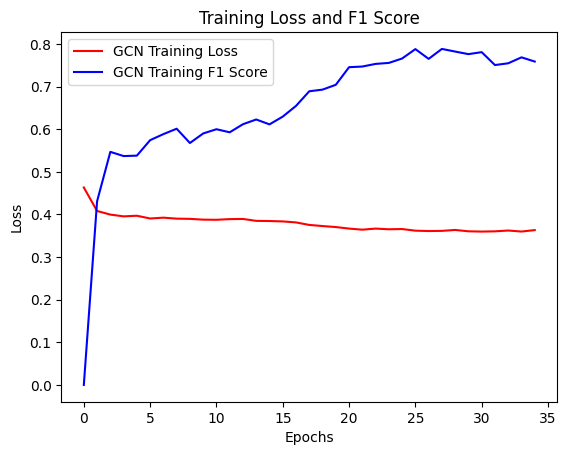

In [16]:
x = np.arange(EPOCHS_GCN, dtype=int)
plt.plot(x, train_losses, color="red", label="GCN Training Loss")
plt.plot(x, train_f1_scores, color="blue", label="GCN Training F1 Score")
plt.title("Training Loss and F1 Score")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [17]:
evaluate_gcn_model(gcn_model, graph_val_loader, vocab_size=vocab_size, device=device)

GCN performance:
Accuracy: 0.9434
Precision: 0.8822
Recall: 0.8510
F1 score: 0.8657
MCC: 0.7326


In [18]:
# PREPARE DATASET FOR GAN MODEL: pad the sequences to make them of same length, then trim them to a fixed sequence length to avoid too much padding.
# convert train_data sequences and val_data sequences into graphs
SEQUENCE_LENGTH = MAX_CALLS  # la GAN genera tracce lunghe quanto quelle usate dalla GCN
train_data_padded = pad_sequence(
    [torch.tensor(sequence, dtype=torch.long) for sequence in train_data],
    batch_first=True,
)
val_data_padded = pad_sequence(
    [torch.tensor(sequence, dtype=torch.long) for sequence in test_data],
    batch_first=True,
)

train_data_padded.shape, val_data_padded.shape

(torch.Size([4165, 4094]), torch.Size([1786, 4494]))

In [19]:
train_data_padded[:, SEQUENCE_LENGTH].shape, val_data_padded[:SEQUENCE_LENGTH].shape

# our dataset will be of shape (n_samples, SEQUENCE_LENGTH).
train_dataset = CustomSequenceDataset(
    train_data_padded[:, :SEQUENCE_LENGTH], train_labels
)
val_dataset = CustomSequenceDataset(val_data_padded[:, :SEQUENCE_LENGTH], test_labels)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [20]:
# hyperparameters of the generator and discriminator of the GAN model
latent_dim = 100
hidden_dim = 128
vocab_size = 342  # we have 342 unique system calls in the ADFA dataset
seq_len = SEQUENCE_LENGTH  # sequence length of the ADFA dataset with less than 120, will be padded. If sequence is longer than 120, it will be truncated.
output_dim = vocab_size
embed_dim = 10
dropout = 0.5
batch_size = 32
#n_samples = 4459  # pareggerebbe le classi sull'intero dataset (5205 benigni - 746 attacchi)
n_samples = 3121  # pareggia le classi nel training set (3643 benigni - 522 attacchi)
num_classes = 2
lr = 5e-5  # 2e-6
epochs = 150
# criterion = nn.BCELoss()
criterion = nn.CrossEntropyLoss()
device = get_device()
temperature = 0.2  # 0.1

gen = Generator(
    latent_dim,
    seq_len,
    hidden_dim,
    output_dim,
    embed_dim,
    dropout,
    conditional_info=True,
    num_classes=num_classes,
).to(device)
# gen = Gen(latent_dim, hidden_dim, seq_len, output_dim, embed_dim, dropout).to(device)

disc = Discriminator(
    vocab_size,
    seq_len,
    hidden_dim,
    embed_dim,
    dropout,
    conditional_info=True,
    num_classes=num_classes,
).to(device)


# Apply the weights initialization to your GAN model, uncomment the two lines of code below:

#gen.apply(init_weights)
#disc.apply(init_weights)

gen_optimizer = Adam(gen.parameters(), lr=lr, betas=(0.5, 0.999))

disc_optimizer = Adam(disc.parameters(), lr=lr, betas=(0.5, 0.999))

In [21]:
device = get_device()

In [22]:
# input_data = torch.randint(0, vocab_size, (n_samples, seq_len))
# input_labels = torch.randint(0, num_classes, (n_samples,))
# train_dataset = CustomSequenceDataset(input_data, input_labels)
# train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

In [23]:
# note that the temperature is set to any value between 0 and 1.
g_losses, d_losses = train_gan_model(
    gen,
    disc,
    gen_optimizer,
    disc_optimizer,
    train_loader,
    epochs,
    vocab_size,
    device=device,
    tau=temperature,
    warm_up_epochs=0,  # nessun warm-up: generatore e discriminatore si addestrano insieme dalla prima epoca
)

Epoch 1 / 150


100%|██████████| 66/66 [00:01<00:00, 47.32it/s]


D Loss: 1.3431, G Loss: -0.7084
Epoch 2 / 150


100%|██████████| 66/66 [00:01<00:00, 55.74it/s]


D Loss: 1.0200, G Loss: -0.5951
Epoch 3 / 150


100%|██████████| 66/66 [00:01<00:00, 56.22it/s]


... (291 outputs left out)

100%|██████████| 66/66 [00:01<00:00, 48.77it/s]


D Loss: 0.0000, G Loss: -0.0000
Epoch 150 / 150


100%|██████████| 66/66 [00:01<00:00, 44.76it/s]

D Loss: 0.0000, G Loss: -0.0000


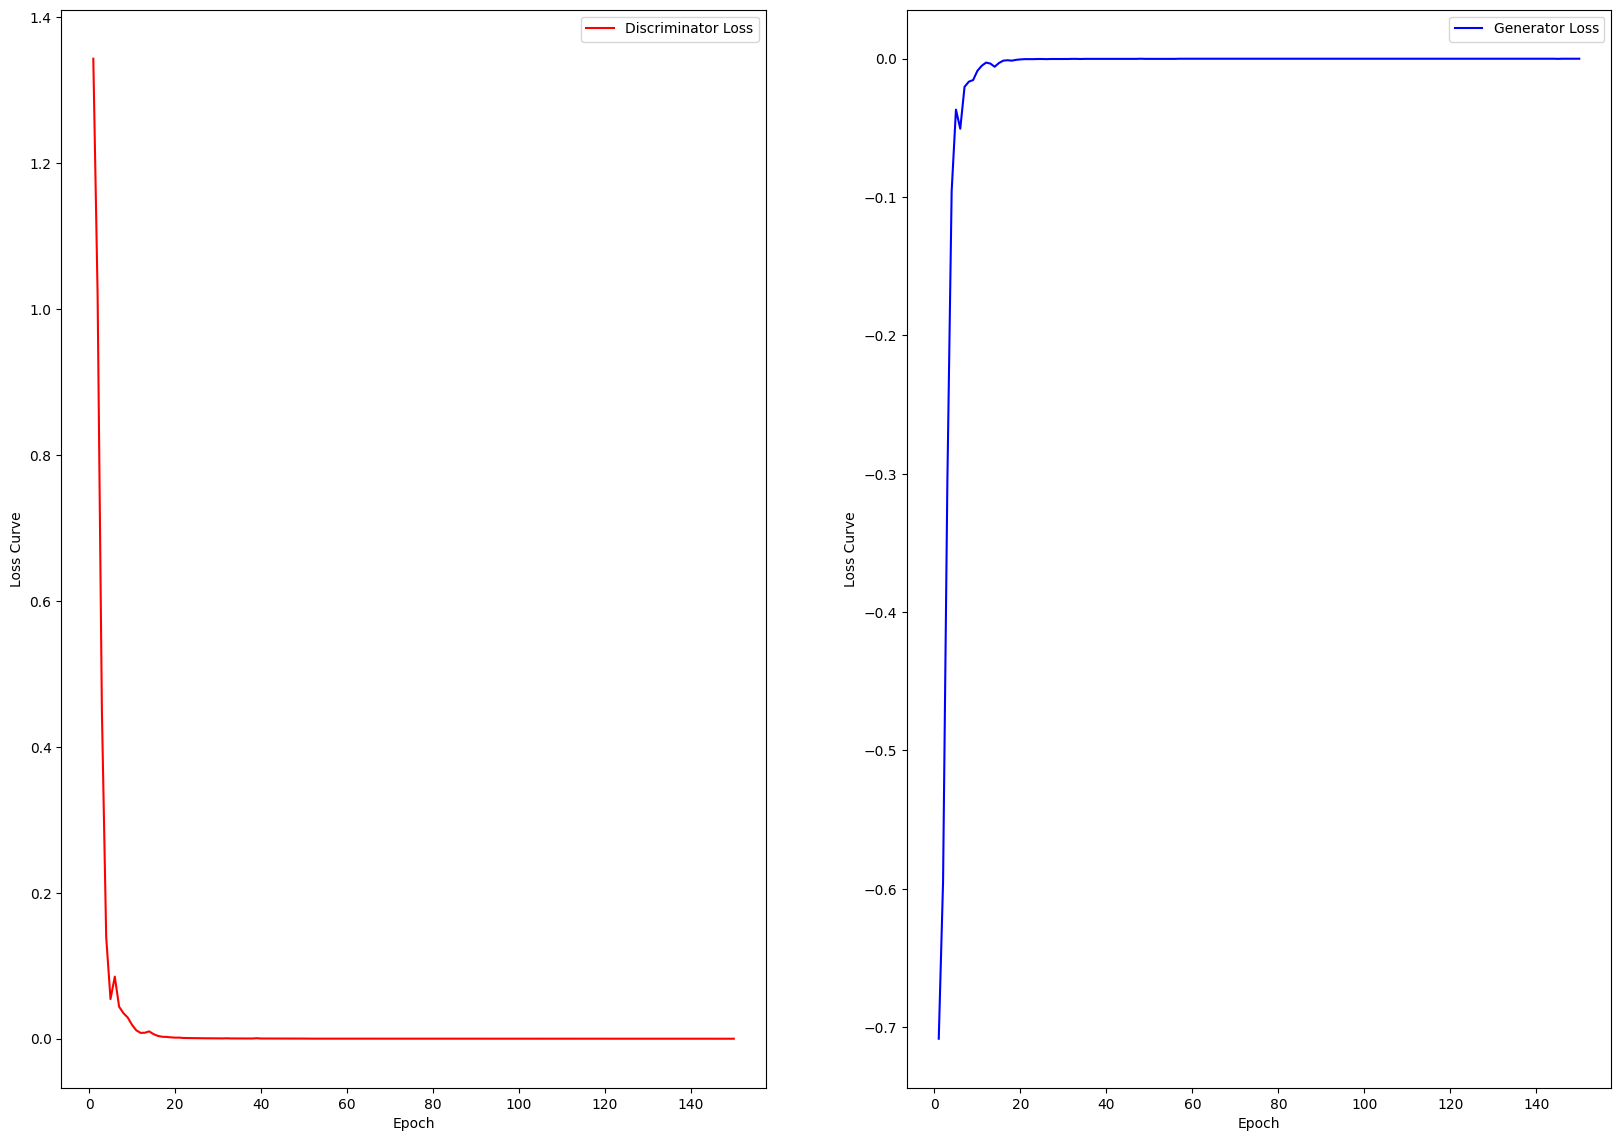

In [24]:
plot_loss_curve(d_losses, g_losses, epochs)

## generate fake samples


In [25]:
#fake_labels = torch.randint(0, num_classes, (n_samples,), dtype=torch.long)
fake_labels = torch.full((n_samples,), 1, dtype=torch.long)  # All labels are 1 (Per far generare solo attacchi)
z = torch.randn((n_samples, latent_dim))

# print("random noise shape", z.shape)
# set generator to eval mode
gen.eval()

fake_data = gen(z.to(device), fake_labels.to(device)).detach().cpu()

# print the generated data: if the data contains nan values, it means that there is gradient explosion, or other issues. To avoid such problems, change the termperature value to be between 0.1 and 0.5. Also, trying changing the learning rate to be between 5e-6 and 1e-4. Of course, this is just a suggestion. You might experiment with other values if you want, and report your findings.
print(fake_data)

tensor([[[1.8319e-08, 6.8264e-08, 2.5341e-07,  ..., 2.8023e-10,
          1.1818e-08, 1.1629e-08],
         [1.2993e-09, 2.5070e-10, 4.9347e-11,  ..., 2.3770e-08,
          2.8944e-07, 1.9712e-08],
         [8.7854e-08, 1.2084e-07, 4.0862e-08,  ..., 2.4738e-05,
          1.5015e-06, 3.7893e-07],
         ...,
         [1.1247e-01, 3.0345e-05, 2.0111e-06,  ..., 1.1087e-08,
          1.4165e-08, 3.3771e-09],
         [3.7656e-05, 7.4195e-06, 2.3695e-07,  ..., 1.1084e-07,
          3.1929e-07, 1.9332e-05],
         [7.7313e-10, 8.7350e-09, 1.3833e-09,  ..., 2.7692e-09,
          1.7157e-09, 2.3188e-10]],

        [[9.2132e-08, 4.8469e-06, 1.5008e-07,  ..., 4.3073e-08,
          3.7494e-08, 1.4546e-04],
         [8.3246e-09, 2.9411e-07, 2.3759e-07,  ..., 1.2266e-06,
          5.5053e-07, 7.7417e-08],
         [2.3147e-07, 8.1934e-08, 3.7535e-06,  ..., 1.0781e-07,
          9.1892e-06, 1.6801e-06],
         ...,
         [1.1308e-04, 2.7209e-08, 4.7560e-08,  ..., 1.1190e-08,
          3.579

In [26]:
print(fake_labels.shape)

torch.Size([3121])


In [27]:
# get the generated samples as tokens (this are a sequence tokens or words / characters, represented by integers .)
from pprint import pprint

fake_samples = torch.argmax(fake_data, dim=-1).cpu().numpy()

# now, let's see two generated sequences
pprint(fake_samples[:2])

array([[192,   6,   4,   6,  11,   3, 174, 175,  78, 125,  33, 221,  54,
        174,  54,   3, 195, 102, 102,   5, 192, 240, 162, 102, 168,  33,
         13,   5, 290, 180, 125, 265, 102, 108, 174,   5,   6, 195,   5,
        197, 158,  13,   3, 195,   6,   5, 158, 140,   3, 168, 125,   6,
        221, 109, 219, 219,  78,   4,   5,  78,  13, 195, 192,   6, 197,
          6, 192,  45, 102, 140,   5, 174,   3, 175,   3,   5, 195, 124,
        175, 174, 120,  91,  13,  85,   7, 221, 195, 104, 102, 182,   5,
        102, 140, 192, 140, 240,  13,   5, 174,  33],
       [ 54,   6, 245, 102,  33,   5, 180,  33,  84,   6,  33, 180,  54,
        221,   7, 300, 195,   4,  51, 271, 263, 111, 102, 102, 195,   6,
        221, 168,  58, 156, 175, 214,   4, 162, 174,  78,   6, 174,  43,
        197,   4,  13, 192, 168, 240,  13, 158, 175, 102, 309,   3,   6,
        250,  78, 180, 314, 264, 253,   5,  78,  13, 195, 318, 168, 114,
        265, 192,  78, 102,   5,   5, 174, 265, 168,   3,   5, 219,   

## Pulizia delle tracce generate

Per addestrare la GAN le tracce reali più corte di `SEQUENCE_LENGTH` sono state completate con zeri (padding), quindi anche le tracce generate possono terminare con degli zeri. Li togliamo, perché non sono system call.

In [28]:
def strip_padding(seq):
    """Toglie gli zeri finali di riempimento da una traccia."""
    seq = list(seq)
    while seq and seq[-1] == 0:
        seq.pop()
    return seq


fake_traces = [strip_padding(seq) for seq in fake_samples.tolist()]
fake_traces = [seq for seq in fake_traces if len(seq) >= 2]  # servono almeno due chiamate per avere un arco nel grafo
fake_trace_labels = [1] * len(fake_traces)  # sono tutti attacchi

lengths = [len(seq) for seq in fake_traces]
print(f"Tracce sintetiche utilizzabili: {len(fake_traces)} su {len(fake_samples)}")
if lengths:
    print(f"Lunghezza: media {np.mean(lengths):.1f}, minima {min(lengths)}, massima {max(lengths)}")

Tracce sintetiche utilizzabili: 3121 su 3121
Lunghezza: media 100.0, minima 99, massima 100


# Generazione del grafico dai token generati

` Usando la funzione sequence_to_graph() trovata nel preprocess_data.py`


In [29]:
# convert the generated samples into a networkx graph and also pytorch_geometric graph data object
networkx_graph, pytorch_geometric_data = sequence_to_graph(fake_traces[0])

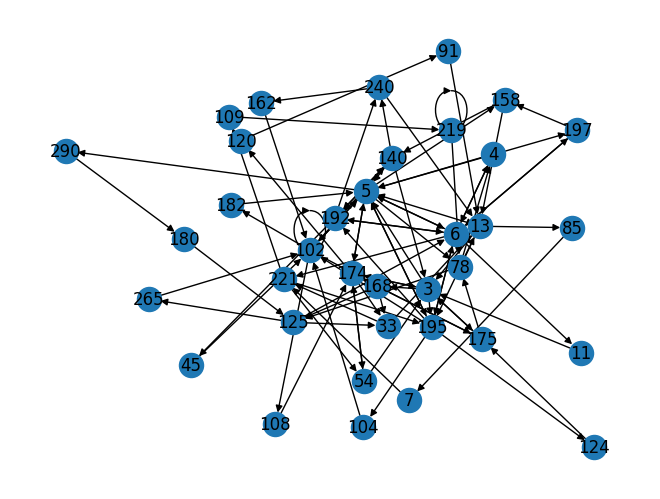

In [30]:
# you can see the networkx graph we generated
nx.draw(networkx_graph, with_labels=True)
plt.show()

# The Remaining Steps:

```
1 - generate many fake samples (sequences and their corresponding labels),[3121 attacchi finti, quanti servono per pareggiare
le classi nel training set: 3643 benigni contro 522 attacchi]

2 - add these fake sequences to train_data sequences, and add their fake_labels (benign or malign) to the trian_labels

3 - train a new GCNModel and compare performance before and after adding fake samples


```


# Aggiunta dei fake maligni generati dalla cGAN solo in train_data

In [31]:
data_1 = benign_train_sequences + benign_val_sequences + attack_sequences
labels_1 = benign_train_labels + benign_val_labels + attack_labels

# perform  70 % training and 30% testing set split

train_data_1, test_data_1, train_labels_1, test_labels_1 = train_test_split(
    data_1, labels_1, test_size=0.3, random_state=42, shuffle=True, stratify=labels_1
)
train_data_1 = train_data_1 + fake_traces
train_labels_1 = train_labels_1 + fake_trace_labels

len(train_data_1), len(train_labels_1), len(test_data_1), len(test_labels_1)

(7286, 7286, 1786, 1786)

In [32]:
# Create a custom dataset
batch_size = 64
# convert train_data sequences and val_data sequences into graphs

# la GCN usa solo le prime MAX_CALLS chiamate di ogni traccia
train_graph_dataset_1 = fetch_graph_data([seq[:MAX_CALLS] for seq in train_data_1], train_labels_1)
val_graph_dataset_1 = fetch_graph_data([seq[:MAX_CALLS] for seq in test_data_1], test_labels_1)


# Create a data loader
graph_train_loader_1 = DataLoader(
    train_graph_dataset_1, batch_size=batch_size, shuffle=True
)
graph_val_loader_1 = DataLoader(val_graph_dataset_1, batch_size=batch_size, shuffle=False)

In [33]:
# you can see the graph data: it has edge_index, weight, num_nodes, y (label of the graph, i.e., malign or benign), and x (node features). Here, x is a list of integers representing the node features. They need to be converted to a one-hot vector of size vocab_size or vector of embedded representation.
train_graph_dataset_1[0]

Data(edge_index=[2, 31], weight=[31], num_nodes=14, x=[1], y=0)

In [34]:
# device = get_device()
vocab_size = 342
hidden_dim = 128  # also the number of hidden nodes in the GCN. Can be set to 128, 256 or 512. If you have more GPU, you can increase it. However, you may face overfitting. Increase dropout if you face overfitting. Like dropout = 0.6, 0.7, 0.8
num_classes = 2
dropout = 0.4
output_dim = num_classes
# number of GCN layers, depending on your GPU, set it to any integer from 2 to 5.
num_layers = 3
EPOCHS_GCN = 35


device = torch.device("cuda")


gcn_model = GCNModel(
    in_channels=vocab_size,
    hidden_channels=hidden_dim,
    out_channels=num_classes,
    num_layers=num_layers,
    dropout=dropout,
).to(device)

train_losses, train_f1_scores = train_gcn_model(
    gcn_model,
    graph_train_loader_1,
    vocab_size=vocab_size,
    epochs=EPOCHS_GCN,
    device=device,
)

100%|██████████| 114/114 [00:01<00:00, 59.46it/s]


Epoch 1 / 35, Loss: 0.4418, F1 Score: 0.8448


100%|██████████| 114/114 [00:01<00:00, 71.81it/s]


Epoch 2 / 35, Loss: 0.3694, F1 Score: 0.9424


100%|██████████| 114/114 [00:01<00:00, 78.69it/s]


Epoch 3 / 35, Loss: 0.3640, F1 Score: 0.9496


... (60 outputs left out)

100%|██████████| 114/114 [00:01<00:00, 84.25it/s]


Epoch 34 / 35, Loss: 0.3499, F1 Score: 0.9632


100%|██████████| 114/114 [00:01<00:00, 66.12it/s]

Epoch 35 / 35, Loss: 0.3500, F1 Score: 0.9638


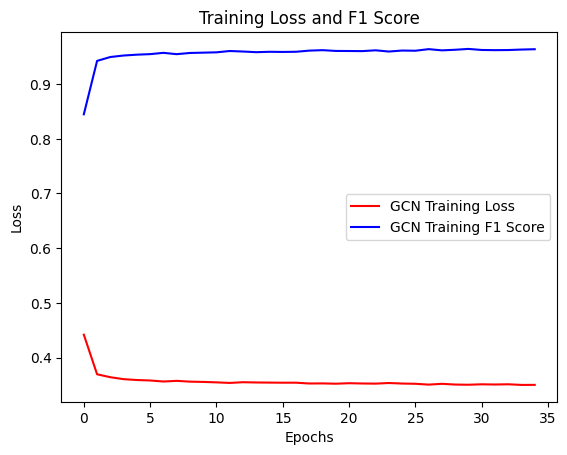

In [35]:
x = np.arange(EPOCHS_GCN, dtype=int)
plt.plot(x, train_losses, color="red", label="GCN Training Loss")
plt.plot(x, train_f1_scores, color="blue", label="GCN Training F1 Score")
plt.title("Training Loss and F1 Score")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [36]:
evaluate_gcn_model(gcn_model, graph_val_loader, vocab_size=vocab_size, device=device)

GCN performance:
Accuracy: 0.9255
Precision: 0.8271
Recall: 0.8408
F1 score: 0.8338
MCC: 0.6678


# Nuovo modello settando iperparametri differenti

` Modificati iperparametri col fine di migliorare le metriche del nuovo modello `


In [37]:
#device = get_device()
vocab_size = 342
hidden_dim = 256  # also the number of hidden nodes in the GCN. Can be set to 128, 256 or 512. If you have more GPU, you can increase it. However, you may face overfitting. Increase dropout if you face overfitting. Like dropout = 0.6, 0.7, 0.8
num_classes = 2
dropout = 0.7
output_dim = num_classes
# number of GCN layers, depending on your GPU, set it to any integer from 2 to 5.
num_layers = 4
EPOCHS_GCN = 100


device = torch.device("cuda")


gcn_model = GCNModel(
    in_channels=vocab_size,
    hidden_channels=hidden_dim,
    out_channels=num_classes,
    num_layers=num_layers,
    dropout=dropout,
).to(device)

train_losses, train_f1_scores = train_gcn_model(
    gcn_model,
    graph_train_loader,
    vocab_size=vocab_size,
    epochs=EPOCHS_GCN,
    device=device,
)

100%|██████████| 66/66 [00:01<00:00, 55.69it/s]


Epoch 1 / 100, Loss: 0.4422, F1 Score: 0.0637


100%|██████████| 66/66 [00:00<00:00, 76.57it/s]


Epoch 2 / 100, Loss: 0.4050, F1 Score: 0.5075


100%|██████████| 66/66 [00:00<00:00, 74.85it/s]


Epoch 3 / 100, Loss: 0.3985, F1 Score: 0.5543


... (190 outputs left out)

100%|██████████| 66/66 [00:00<00:00, 74.14it/s]


Epoch 99 / 100, Loss: 0.3598, F1 Score: 0.7946


100%|██████████| 66/66 [00:00<00:00, 74.57it/s]

Epoch 100 / 100, Loss: 0.3618, F1 Score: 0.7828


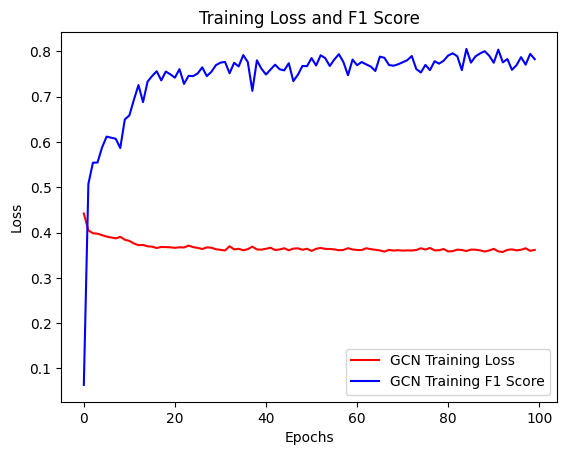

In [38]:
x = np.arange(EPOCHS_GCN, dtype=int)
plt.plot(x, train_losses, color="red", label="GCN Training Loss")
plt.plot(x, train_f1_scores, color="blue", label="GCN Training F1 Score")
plt.title("Training Loss and F1 Score")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [39]:
evaluate_gcn_model(gcn_model, graph_val_loader, vocab_size=vocab_size, device=device)

GCN performance:
Accuracy: 0.9423
Precision: 0.8913
Recall: 0.8313
F1 score: 0.8578
MCC: 0.7201


Modello con nuovi iperparametri e fake sample solo su train_data

In [40]:
data_1 = benign_train_sequences + benign_val_sequences + attack_sequences
labels_1 = benign_train_labels + benign_val_labels + attack_labels

# perform  70 % training and 30% testing set split

train_data_1, test_data_1, train_labels_1, test_labels_1 = train_test_split(
    data_1, labels_1, test_size=0.3, random_state=42, shuffle=True, stratify=labels_1
)
train_data_1 = train_data_1 + fake_traces
train_labels_1 = train_labels_1 + fake_trace_labels

len(train_data_1), len(train_labels_1), len(test_data_1), len(test_labels_1)

(7286, 7286, 1786, 1786)

In [41]:
# Create a custom dataset
batch_size = 64
# convert train_data sequences and val_data sequences into graphs

# la GCN usa solo le prime MAX_CALLS chiamate di ogni traccia
train_graph_dataset_1 = fetch_graph_data([seq[:MAX_CALLS] for seq in train_data_1], train_labels_1)
val_graph_dataset_1 = fetch_graph_data([seq[:MAX_CALLS] for seq in test_data_1], test_labels_1)


# Create a data loader
graph_train_loader_1 = DataLoader(
    train_graph_dataset_1, batch_size=batch_size, shuffle=True
)
graph_val_loader_1 = DataLoader(val_graph_dataset_1, batch_size=batch_size, shuffle=False)

In [42]:
vocab_size = 342
hidden_dim = 256  # also the number of hidden nodes in the GCN. Can be set to 128, 256 or 512. If you have more GPU, you can increase it. However, you may face overfitting. Increase dropout if you face overfitting. Like dropout = 0.6, 0.7, 0.8
num_classes = 2
dropout = 0.7
output_dim = num_classes
# number of GCN layers, depending on your GPU, set it to any integer from 2 to 5.
num_layers = 4
EPOCHS_GCN = 100


device = torch.device("cuda")


gcn_model = GCNModel(
    in_channels=vocab_size,
    hidden_channels=hidden_dim,
    out_channels=num_classes,
    num_layers=num_layers,
    dropout=dropout,
).to(device)

train_losses, train_f1_scores = train_gcn_model(
    gcn_model,
    graph_train_loader_1,
    vocab_size=vocab_size,
    epochs=EPOCHS_GCN,
    device=device,
)

100%|██████████| 114/114 [00:01<00:00, 61.32it/s]


Epoch 1 / 100, Loss: 0.4301, F1 Score: 0.8424


100%|██████████| 114/114 [00:01<00:00, 63.76it/s]


Epoch 2 / 100, Loss: 0.3678, F1 Score: 0.9454


100%|██████████| 114/114 [00:01<00:00, 63.88it/s]


Epoch 3 / 100, Loss: 0.3657, F1 Score: 0.9458


... (190 outputs left out)

100%|██████████| 114/114 [00:01<00:00, 66.19it/s]


Epoch 99 / 100, Loss: 0.3460, F1 Score: 0.9665


100%|██████████| 114/114 [00:01<00:00, 65.14it/s]

Epoch 100 / 100, Loss: 0.3469, F1 Score: 0.9657


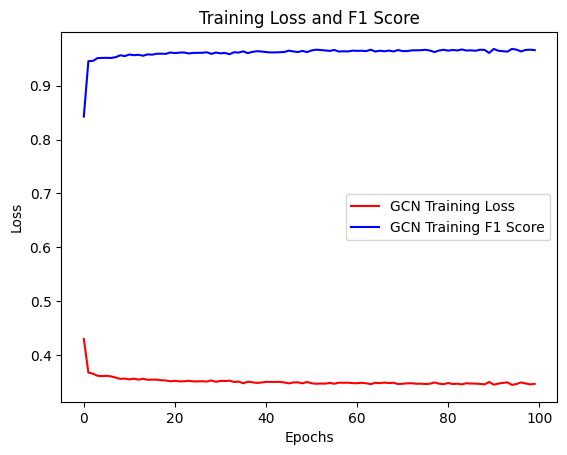

In [43]:
x = np.arange(EPOCHS_GCN, dtype=int)
plt.plot(x, train_losses, color="red", label="GCN Training Loss")
plt.plot(x, train_f1_scores, color="blue", label="GCN Training F1 Score")
plt.title("Training Loss and F1 Score")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [44]:
evaluate_gcn_model(gcn_model, graph_val_loader, vocab_size=vocab_size, device=device)

GCN performance:
Accuracy: 0.9395
Precision: 0.8719
Recall: 0.8431
F1 score: 0.8567
MCC: 0.7144


# Confronto strutturale: grafi generati e attacchi reali

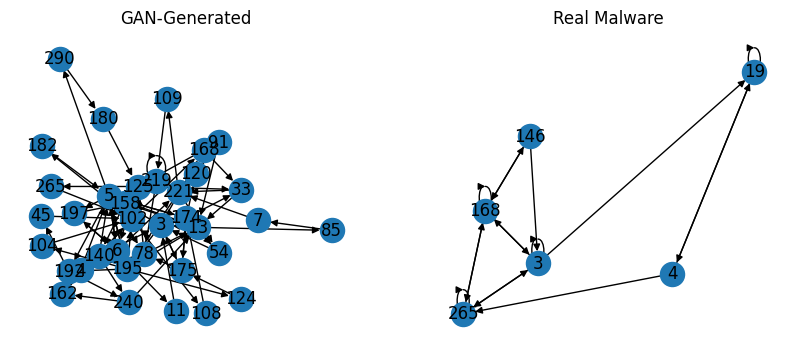

Media ± deviazione standard: 3121 grafi generati, 746 attacchi reali
-     average_degree: generati     4.753 ± 0.564 | reali     4.381 ± 1.000
-     avg_clustering: generati     0.202 ± 0.069 | reali     0.620 ± 0.318
-    avg_betweenness: generati     0.041 ± 0.002 | reali     0.065 ± 0.056
-            density: generati     0.134 ± 0.033 | reali     0.984 ± 0.709
-           diameter: generati     4.854 ± 0.862 | reali     2.567 ± 1.470
-  avg_shortest_path: generati     2.481 ± 0.268 | reali     1.532 ± 0.543

Grafi generati giudicati simili agli attacchi reali: 74.3%
Attacchi reali che passano lo stesso controllo (termine di paragone): 86.2%


In [45]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# 1) Helpers semplici
def to_undirected_if_needed(G):
    return G if not G.is_directed() else G.to_undirected()

def analyze_graph(G: nx.Graph):
    """Ritorna un dizionario con poche metriche robuste e veloci."""
    U = to_undirected_if_needed(G)
    degs = [d for _, d in U.degree()]
    n = U.number_of_nodes()

    # valori None se grafo vuoto
    if n == 0:
        return dict(
            average_degree=None, avg_clustering=None, avg_betweenness=None,
            density=None, diameter=None, avg_shortest_path=None
        )

    metrics = {}
    metrics["average_degree"] = float(np.mean(degs))
    metrics["avg_clustering"] = float(np.mean(list(nx.clustering(U).values())))
    metrics["avg_betweenness"] = float(np.mean(list(nx.betweenness_centrality(U).values())))
    metrics["density"] = nx.density(U)

    # path-based solo se il grafo è connesso
    if nx.is_connected(U):
        metrics["diameter"] = nx.diameter(U)
        metrics["avg_shortest_path"] = nx.average_shortest_path_length(U)
    else:
        metrics["diameter"] = None
        metrics["avg_shortest_path"] = None

    return metrics

def mean_std_dict(list_of_metric_dicts):
    """Media e std per ogni metrica ignorando i None."""
    keys = list_of_metric_dicts[0].keys()
    means, stds = {}, {}
    for k in keys:
        vals = [d[k] for d in list_of_metric_dicts if d[k] is not None]
        means[k] = float(np.mean(vals)) if vals else None
        stds[k]  = float(np.std(vals, ddof=0)) if vals else None
    return means, stds

def z_scores(fake_metrics, means, stds):
    """Calcola z-score per ogni metrica (None se impossibile)."""
    z = {}
    for k, v in fake_metrics.items():
        mu, sd = means.get(k), stds.get(k)
        if (v is None) or (mu is None) or (sd is None) or (sd == 0):
            z[k] = None
        else:
            z[k] = (v - mu) / sd
    return z

Z_THR = 2.0  # soglia di similarità |z| <= Z_THR


def is_similar(metrics, means, stds):
    """Vero se tutte le metriche del grafo stanno entro Z_THR deviazioni standard dalla media degli attacchi reali."""
    z = z_scores(metrics, means, stds)
    return all((v is not None) and abs(v) <= Z_THR for v in z.values())


def fmt(mean, std):
    return "n/d" if mean is None else f"{mean:.3f} ± {std:.3f}"


# 2) Disegna un grafo generato e un attacco reale (prime MAX_CALLS chiamate, come nel classificatore)
gen_nx, _ = sequence_to_graph(fake_traces[0])
real_nx, _ = sequence_to_graph(attack_sequences[745][:MAX_CALLS])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); nx.draw(gen_nx, with_labels=True);  plt.title("GAN-Generated")
plt.subplot(1, 2, 2); nx.draw(real_nx, with_labels=True); plt.title("Real Malware")
plt.show()

# 3) Statistiche degli attacchi reali e di tutti i grafi generati
real_graphs = [sequence_to_graph(seq[:MAX_CALLS])[0] for seq in attack_sequences]
real_metrics = [analyze_graph(g) for g in real_graphs]
means, stds = mean_std_dict(real_metrics)

fake_graphs = [sequence_to_graph(seq)[0] for seq in fake_traces]
fake_metrics = [analyze_graph(g) for g in fake_graphs]
fake_means, fake_stds = mean_std_dict(fake_metrics)

print(f"Media ± deviazione standard: {len(fake_graphs)} grafi generati, {len(real_graphs)} attacchi reali")
for k in means:
    print(f"- {k:>18s}: generati {fmt(fake_means[k], fake_stds[k]):>17s} | reali {fmt(means[k], stds[k]):>17s}")

# 4) Quanti grafi passano il controllo |z| <= Z_THR su tutte le metriche
share_fake = np.mean([is_similar(m, means, stds) for m in fake_metrics])
share_real = np.mean([is_similar(m, means, stds) for m in real_metrics])
print(f"\nGrafi generati giudicati simili agli attacchi reali: {share_fake:.1%}")
print(f"Attacchi reali che passano lo stesso controllo (termine di paragone): {share_real:.1%}")

# Conclusioni

Metriche sul test set (1786 tracce, di cui 224 attacchi), usando solo le prime 100 chiamate di ogni traccia. Precision, recall e F1 sono medie macro sulle due classi.

| Classificatore GCN | Training | Accuracy | Precision | Recall | F1 | MCC |
| --- | --- | --- | --- | --- | --- | --- |
| 3 layer, hidden 128, dropout 0,4, 35 epoche | solo dati reali | 0,9434 | 0,8822 | 0,8510 | 0,8657 | 0,7326 |
| 3 layer, hidden 128, dropout 0,4, 35 epoche | + 3121 attacchi sintetici | 0,9255 | 0,8271 | 0,8408 | 0,8338 | 0,6678 |
| 4 layer, hidden 256, dropout 0,7, 100 epoche | solo dati reali | 0,9423 | 0,8913 | 0,8313 | 0,8578 | 0,7201 |
| 4 layer, hidden 256, dropout 0,7, 100 epoche | + 3121 attacchi sintetici | 0,9395 | 0,8719 | 0,8431 | 0,8567 | 0,7144 |

Anche senza warm-up gli attacchi sintetici non migliorano il classificatore: con la prima configurazione lo peggiorano, con la seconda lo lasciano quasi invariato. Il calo è molto più piccolo che nella versione originale, ma la GAN continua a non imparare: il discriminatore prende il sopravvento già alla quinta epoca e dalla decima la loss del generatore resta vicina a zero. I grafi generati sono diversi da quelli degli attacchi reali (clustering medio 0,20 contro 0,62, densità 0,13 contro 0,98) e molto simili tra loro. Il controllo con soglia di 2 deviazioni standard ne accetta il 74%, ma accetta anche solo l'86% degli attacchi reali: è troppo permissivo per dire che sono realistici. L'analisi completa è nel README.